In [1]:
import torch
import numpy as np
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
from tqdm.notebook import tqdm

mnist = datasets.MNIST(root="data", train=True, download=True,
                       transform=transforms.ToTensor())
images = (mnist.data > 0.5).float()

100%|██████████| 9.91M/9.91M [00:00<00:00, 42.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.10MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.50MB/s]


Animation code

In [2]:
# builds a matplotlib animation that shows each frame (a length-784 vector) as a 28x28 image
def make_anim(frames, interval=50, vmin=-1,vmax=1):
    fig, ax = plt.subplots(figsize=(3, 3))
    im = ax.imshow(frames[0].view(28, 28).numpy(), cmap="gray", vmin=vmin, vmax=vmax)
    ax.axis("off")

    # swaps in frame k's pixels for the k-th animation step
    def update(k):
        im.set_data(frames[k].view(28, 28).numpy())
        return [im]

    anim = animation.FuncAnimation(fig, update, frames=len(frames), interval=interval)
    plt.close(fig)
    return anim

Initialization options

In [3]:
# flips the sign of each pixel of a ±1 image with probability 0.3 (modifies img in place)
def corrupt(img):
    for pixel in img:
        if torch.rand(1) < 0.3:
            pixel *= -1
    return img

# picks a random stored pattern and returns a corrupted copy of it as a starting state
def random_corruption():
    a = torch.randint(0,len(patterns),(1,)).item()
    return corrupt(patterns[a])

# returns a random 0/1 vector of length 784 as a starting state
def random_start():
    return torch.randint(0,2,(784,)).float()

# Hopfield network

data

In [4]:
storage = range(10)
idx = [(mnist.targets == d).nonzero()[0].item() for d in storage]
imgs = images[idx]

In [5]:
# flattens 0/1 images to vectors and maps them to ±1
def to_pattern(img):
    return img.flatten(start_dim=1)*2 - 1

patterns = to_pattern(imgs)

Store patterns in weights

In [6]:
# Hebbian rule
# weights = 1/784 * (patterns.T @ patterns)
# weights.fill_diagonal_(0);

#Pseudo-inverse rule
Q = patterns @ patterns.T
weights = patterns.T @ torch.linalg.inv(Q) @ patterns

Generate numbers

In [7]:
# runs asynchronous Hopfield updates (random order) until no unit changes;
# returns the final state and, if frame=True, snapshots every `framerate` steps
def sample(start, frame = False, framerate=20):
    s = start
    frames = [s.clone()]
    update = True
    step = 0
    while update:
        update = False
        for i in torch.randperm(len(s)):
            new_sign = (weights[i] @ s > 0).float() * 2 - 1
            if new_sign != s[i]:
                s[i] = new_sign
                update = True
            step +=1
            if frame and step % framerate == 0 and update:
                frames.append(s.clone())

    frames.append(s.clone())
    return s,frames

Animation

In [8]:
output, frames = sample(random_start(), frame=True)

anim = make_anim(frames)
display(HTML(anim.to_jshtml(default_mode='once')))

In [9]:
anim_w_end = make_anim(frames + [frames[-1]]*20)
anim_w_end.save("hopfield six.gif", writer=animation.PillowWriter(fps=20), dpi=100)

In [10]:
mixture = torch.sign(patterns.sum(0))                    # majority vote (use an odd number of patterns to avoid ties)
print(torch.equal(output, mixture))

False


### Review

this could be thought of in two ways. in some sense it is a recurrent neural network capable of recognizing corrupted versions of stored images. from the perspective of image generation, it is a really expensive model that performs worse than a simple array.

Interestingly, recovery is guaranteed in one pass for <=2 images, and will never work for >2 images. In the latter case, the updating process always converges to the sum of the stored patterns. It might work if the pictures were uncorrelated.

Regardless, the animations are very cool.

Edit: The pseudo-inverse rule works quite well!

# Boltzmann Machine

In [11]:
# n: number of mnist images to include in training data
n = 100
# h: number of hidden units
h = 20
# number of neurons
N = 784+h
# learning rate
eta = 0.01

In [14]:
# flattens 0-1 images to vectors
def to_01pattern(img):
    return img.flatten(start_dim=1)

# training data: list of n vectors of length 784 with entries in {0,1}
patterns = to_01pattern(images[:n])

In [15]:
# model parameters
b = torch.zeros(N)
W = 0.01*torch.randn((N, N))

Gradient descent

In [ ]:
# negative phase: Gibbs-samples the whole network from a random start and returns
# the average unit-unit correlation <s s^T> over the second half of the chain
def sample_free(W, b, iters):
    signal = torch.randint(0,2,(N,)).float()
    total = torch.zeros(N, N)
    count = 0
    for k in range(iters):
        l = torch.randint(0,N,(1,)).item()
        p_flip = torch.sigmoid(W[l] @ signal + b[l])
        signal[l] = torch.bernoulli(p_flip)
        if k > iters/2 and k%N == 0:
            total += torch.outer(signal,signal)
            count += 1
    return total/count

# positive phase: clamps the visible units to a training image, Gibbs-samples only the
# hidden units, and returns the average correlation <s s^T> over the second half
def sample_clamped(W, b, iters):
    # selects a random training image, and random values for hidden units
    vis = patterns[torch.randint(0,n,(1,)).item()]
    hid = torch.randint(0,2,(h,)).float()
    # initializes vector and sum
    signal = torch.concat((vis, hid), dim=0)
    total = torch.zeros(N, N)
    count = 0
    for k in range(iters):
        l = torch.randint(N-h,N,(1,)).item()
        p_flip = torch.sigmoid(W[l] @ signal + b[l])
        signal[l] = torch.bernoulli(p_flip)
        if k > iters/2:
            total += torch.outer(signal,signal)
            count += 1
    return total/count

# estimates the gradient of the negative log-likelihood w.r.t. W: <ss^T>_free - <ss^T>_clamped
def gradient(W, b, iters_free, iters_clamped):
    corr_free = sample_free(W,b,iters_free)
    corr_clamped = sample_clamped(W,b,iters_clamped)
    return corr_free - corr_clamped


# runs `iters` steps of gradient descent on W (no self-connections); b is left untrained
def train(W, b, iters=10000, iters_free=16000, iters_clamped=200):
    for k in tqdm(range(iters), desc="Gradient descent"):
        W = W - eta*gradient(W,b,iters_free, iters_clamped)
        W.fill_diagonal_(0)
    return W

In [ ]:
W = train(W, b, iters=1000)

Gradient descent:   0%|          | 0/1000 [00:00<?, ?it/s]

Generation

In [ ]:
# runs `duration` Gibbs sweeps starting from `start` (plus random hidden units); frames hold
# each visible pixel's p(on) given the current state, followed by the hidden states
def generate_boltzmann(start, duration=1000, frame = False, framerate=20):
    s = torch.concat((start, torch.randint(0,2,(h,)).float()))
    frames = [s.clone()]
    for i in tqdm(range(duration),desc="Generating animation"):
        for k in torch.randperm(len(s)):
            p_flip = torch.sigmoid(W[k] @ s + b[k])
            s[k] = torch.bernoulli(p_flip)
        if i % framerate == 0:
            probs = torch.sigmoid(s @ W.T + b)   # each unit's p(on) given the current state
            frames.append(torch.cat((probs[:784], s[784:])))

    probs = torch.sigmoid(s @ W.T + b)   # each unit's p(on) given the current state
    frames.append(torch.cat((probs[:784], s[784:])))
    return s,frames

Animation

In [ ]:
output, frames = generate_boltzmann(patterns[0], duration=50, frame=True, framerate=1)

Generating animation:   0%|          | 0/50 [00:00<?, ?it/s]

In [ ]:
anim = make_anim([s[:784] for s in frames], vmin=0)
display(HTML(anim.to_jshtml(default_mode='once')))

In [ ]:
anim_w_end = make_anim([s[:784] for s in frames[:500]] + [frames[500][:784]]*20, vmin=0)
anim_w_end.save("bruh.gif", writer=animation.PillowWriter(fps=20), dpi=100)

In [ ]:
np.array(frames).shape

(402002, 804)

# Restricted Boltzmann Machine

Same idea as the Boltzmann machine, but with no visible-visible or hidden-hidden connections. The units in each layer are then conditionally independent given the other layer, so a whole layer can be sampled at once (block Gibbs sampling) and the clamped phase needs no sampling at all.

In [16]:
# n_rbm: number of mnist images to include in training data
n_rbm = 10000
# number of visible and hidden units
n_vis = 784
n_hid = 128
# learning rate
eta_rbm = 0.05
# minibatch size (also the number of persistent fantasy chains)
batch = 100

In [17]:
# training data: n_rbm vectors of length 784 with entries in {0,1}
patterns_rbm = to_01pattern(images[:n_rbm])

In [18]:
# model parameters: only visible-hidden weights, plus a bias for each layer
W_rbm = 0.01*torch.randn((n_vis, n_hid))
b_vis = torch.zeros(n_vis)
b_hid = torch.zeros(n_hid)

Gradient descent

In [19]:
# p(h=1 | v) for each hidden unit; works on a single vector or a batch of rows
def hid_given_vis(v, W, b_hid):
    return torch.sigmoid(v @ W + b_hid)

# p(v=1 | h) for each visible unit; works on a single vector or a batch of rows
def vis_given_hid(hd, W, b_vis):
    return torch.sigmoid(hd @ W.T + b_vis)

# negative phase: advances persistent fantasy chains by k block-Gibbs steps (v -> h -> v)
# and returns the averaged statistics <v h^T>, <v>, <h> along with the updated chains
def sample_free(W, b_vis, b_hid, chains, k=1):
    v = chains
    for _ in range(k):
        hd = torch.bernoulli(hid_given_vis(v, W, b_hid))
        v = torch.bernoulli(vis_given_hid(hd, W, b_vis))
    ph = hid_given_vis(v, W, b_hid)          # use probabilities for the hidden side to reduce noise
    return v.T @ ph / len(v), v.mean(0), ph.mean(0), v

# positive phase: clamps the visible units to a minibatch of training images; since the
# hidden units are independent given v, their expectations are exact, so no sampling is needed
def sample_clamped(W, b_hid, v):
    ph = hid_given_vis(v, W, b_hid)
    return v.T @ ph / len(v), v.mean(0), ph.mean(0)

# gradient of the negative log-likelihood for W, b_vis, b_hid: free minus clamped statistics
def gradient_rbm(W, b_vis, b_hid, v_data, chains, k=1):
    vh_c, v_c, h_c = sample_clamped(W, b_hid, v_data)
    vh_f, v_f, h_f, chains = sample_free(W, b_vis, b_hid, chains, k)
    return vh_f - vh_c, v_f - v_c, h_f - h_c, chains

# persistent contrastive divergence: for each epoch, loops over shuffled minibatches and
# takes one gradient step per batch, carrying the fantasy chains over between steps
def train_rbm(W, b_vis, b_hid, epochs=20, k=1):
    chains = torch.randint(0, 2, (batch, n_vis)).float()
    for epoch in tqdm(range(epochs), desc="Gradient descent"):
        for idx in torch.randperm(n_rbm).split(batch):
            dW, dbv, dbh, chains = gradient_rbm(W, b_vis, b_hid, patterns_rbm[idx], chains, k)
            W = W - eta_rbm*dW
            b_vis = b_vis - eta_rbm*dbv
            b_hid = b_hid - eta_rbm*dbh
    return W, b_vis, b_hid

In [20]:
W_rbm, b_vis, b_hid = train_rbm(W_rbm, b_vis, b_hid, epochs=20)

Gradient descent:   0%|          | 0/20 [00:00<?, ?it/s]

Generation

In [21]:
# runs `duration` block-Gibbs steps starting from `start`; frames hold each visible pixel's
# p(on) given the current hidden state, followed by the hidden states
def generate_rbm(start, duration=1000, frame=False, framerate=20):
    v = start.clone()
    hd = torch.bernoulli(hid_given_vis(v, W_rbm, b_hid))
    frames = [torch.cat((v, hd))]
    for i in tqdm(range(duration), desc="Generating animation"):
        v = torch.bernoulli(vis_given_hid(hd, W_rbm, b_vis))
        hd = torch.bernoulli(hid_given_vis(v, W_rbm, b_hid))
        if frame and i % framerate == 0:
            frames.append(torch.cat((vis_given_hid(hd, W_rbm, b_vis), hd)))

    frames.append(torch.cat((vis_given_hid(hd, W_rbm, b_vis), hd)))
    return torch.cat((v, hd)), frames

Animation

In [22]:
output, frames = generate_rbm(random_start(), duration=500, frame=True, framerate=2)

Generating animation:   0%|          | 0/500 [00:00<?, ?it/s]

In [23]:
anim = make_anim([s[:784] for s in frames], vmin=0)
display(HTML(anim.to_jshtml(default_mode='once')))

In [24]:
anim_w_end = make_anim([s[:784] for s in frames] + [frames[-1][:784]]*20, vmin=0)
anim_w_end.save("rbm.gif", writer=animation.PillowWriter(fps=20), dpi=100)

Sampling:   0%|          | 0/1000 [00:00<?, ?it/s]

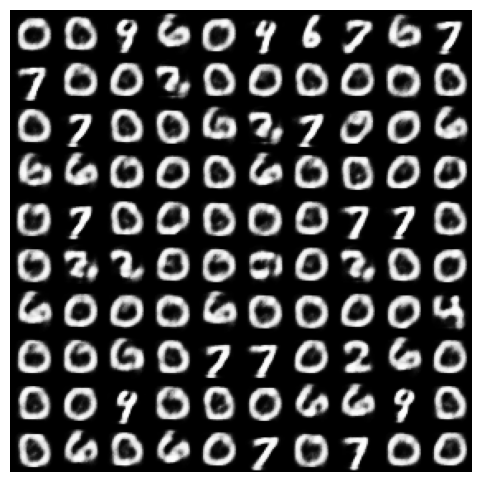

In [26]:
# runs 100 independent chains in parallel from sparse random starts, then shows each
# chain's final visible probabilities as one tile of a 10x10 grid
def sample_grid(steps=1000, density=0.13):
    v = torch.bernoulli(torch.full((100, n_vis), density))   # ~13% ink, like real digits
    for _ in tqdm(range(steps), desc="Sampling"):
        hd = torch.bernoulli(hid_given_vis(v, W_rbm, b_hid))
        v = torch.bernoulli(vis_given_hid(hd, W_rbm, b_vis))
    probs = vis_given_hid(hd, W_rbm, b_vis)
    # arrange the 100 images (each 28x28) into one 280x280 picture
    grid = probs.view(10, 10, 28, 28).permute(0, 2, 1, 3).reshape(280, 280)
    plt.figure(figsize=(6, 6))
    plt.imshow(grid.numpy(), cmap="gray", vmin=0, vmax=1)
    plt.axis("off")
    plt.show()
    return probs

grid_samples = sample_grid()